# PIMC - Proton in a double well potential

In [71]:
import numpy as np
import scipy.constants as const
from dataclasses import dataclass

@dataclass
class SimulationParams:
    P: int
    N: int
    C: float
    a: float
    m: float
    V0: float
    T: float
    omega_P: float
    dx: float

# Functions
def random_displacement(dx: float) -> float:
    """
    dx: Maximum displacement
    Generate a random displacement following dx*(eta-0.5), where eta is a uniform random number in [0, 1].
    """
    eta = np.random.uniform(0, 1)
    return dx * (2 * eta - 1)

def V(x: float, a: float, V0: float) -> float:
    """
    x: Position
    a: Potential length parameter
    V0: Potential energy parameter
    Potential energy function.
    """
    return V0 * ((x / a)**2 - 1)**2

def Delta_U(state: np.ndarray, bead_index: int, displacement: float, params: SimulationParams) -> float:
    """
    state: Current state of the system (positions of beads)
    bead_index: Index of the bead to be displaced
    displacement: Amount of displacement for the bead
    params: Simulation parameters
    Calculate the change in potential energy for a given bead index and displacement.
    """
    # Compute the diff in potential energy
    V_diff = (1/params.P) * (V(state[bead_index] + displacement, params.a, params.V0) - V(state[bead_index], params.a, params.V0))

    # Compute the diff in spring energy
    xj_old = state[bead_index]
    xj_new = xj_old + displacement
    xjp = state[(bead_index + 1) % params.P]
    xjm = state[(bead_index - 1) % params.P]
    spring_diff = 0.5 * params.m * params.omega_P**2 * ((xjp - xj_new)**2 + (xj_new - xjm)**2 - (xjp - xj_old)**2 - (xj_old - xjm)**2)
    return V_diff + spring_diff

def metropolis_acceptance(delta_U: float, params: SimulationParams) -> bool:
    """
    delta_U: Change in energy
    params: Simulation parameters
    Metropolis acceptance criterion.
    """
    if delta_U < 0:
        return True
    else:
        acceptance_prob = np.exp(-delta_U / (const.k * params.T))
        return np.random.uniform(0, 1) <= acceptance_prob

def algo_step(M_conf: np.ndarray, success_list: np.ndarray, i: int, params: SimulationParams):
    """
    M_conf: Configuration matrix for beads
    success_list: List to store success rates
    i: Current iteration index
    params: Simulation parameters
    Perform a single step of the Metropolis algorithm.
    """
    # Randomly select a bead index
    bead_index = np.random.randint(0, params.P)

    # Generate a random displacement
    displacement = random_displacement(params.dx)

    # Calculate the change in potential energy
    delta_U = Delta_U(M_conf[i, :], bead_index, displacement, params)

    # Decide whether to accept the move
    M_conf[i+1, :] = M_conf[i, :] # Copy previous configuration
    if metropolis_acceptance(delta_U, params):
        M_conf[i+1, bead_index] += displacement
        success_list[i] = 1  # Move accepted
    else:
        success_list[i] = 0  # Move rejected

def run_simulation(N: int = 20000, P: int = 50, C: float = 0.3):
    """
    N: Number of iterations
    P: Number of beads
    C: Unit reduction factor
    Run the Metropolis algorithm for N iterations.
    """

    # Constants
    a = 0.04e-9 # Potential lenght parameter
    m = const.m_p # proton mass
    V0 = const.hbar**2 / (2 * m * a**2 * C) # Potential energy parameter
    T = 0.4 * V0 / const.k # Simulation temperature
    omega_P = np.sqrt(P) * const.k * T / const.hbar # Quantum spring frequency
    P_ref = 50 # Reference number of beads for dx calculation
    dx_ref = 0.4 * a # Reference spatial step size
    dx = dx_ref * np.sqrt(P_ref / P) # Adjusted spatial step size to maintain a similar acceptance rate (45%)
    params = SimulationParams(
        P=P,
        N=N, 
        C=C, 
        a=a, 
        m=m, 
        V0=V0, 
        T=T, 
        omega_P=omega_P, 
        dx=dx,
        )

    # Initialization
    M_conf = a*np.ones((N+1, params.P)) # Configuration matrix for beads
    success_list = np.zeros(N, dtype=int) # List to store success rates
    

    for i in range(int(N)):
        algo_step(M_conf, success_list, i, params)

    return (M_conf, success_list, params)

# Run simulation

In [72]:
M_conf, success_list, params = run_simulation(10000, 30)

# Result analysis

Success rate: 46.40%
Mean energy: 2.6631e-03 eV
Variance of energy: 1.4062e-06 eV^2
Mean centroid position: 4.0604e-11 m
Mean controid position (reduced units): 1.0151e+00 a
Variance of centroid position: 1.3579e-25 m^2


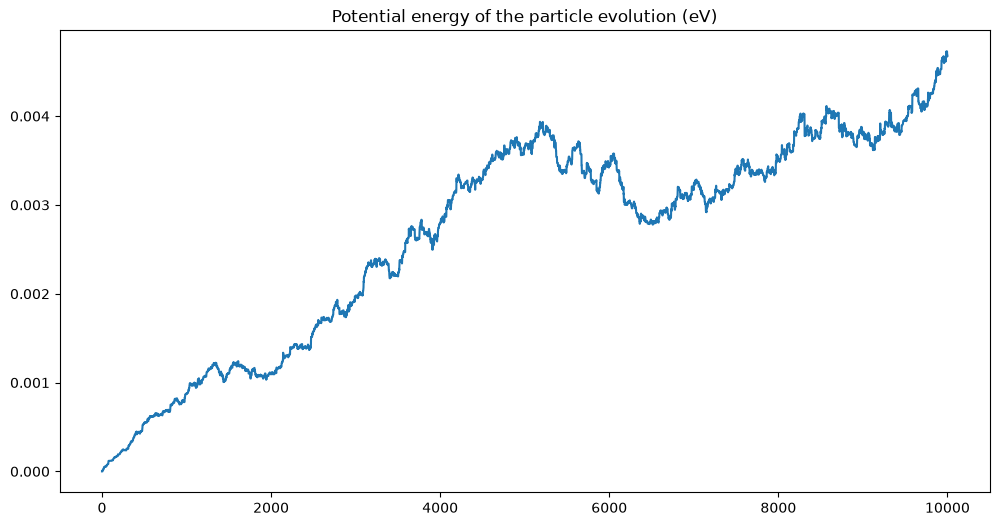

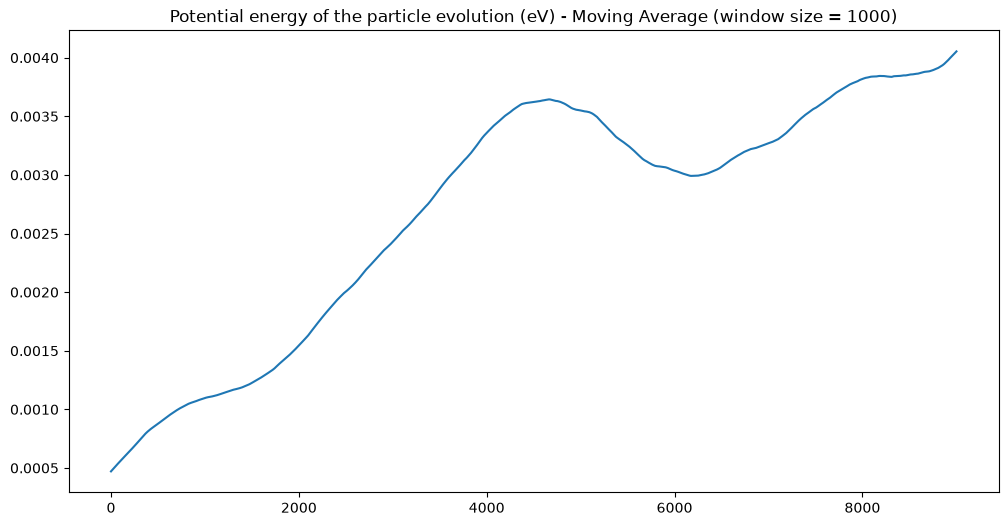

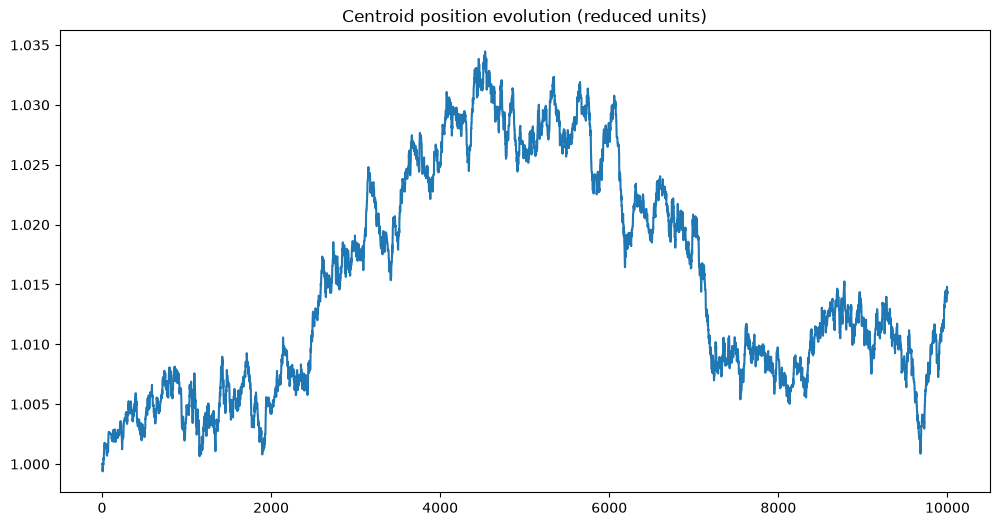

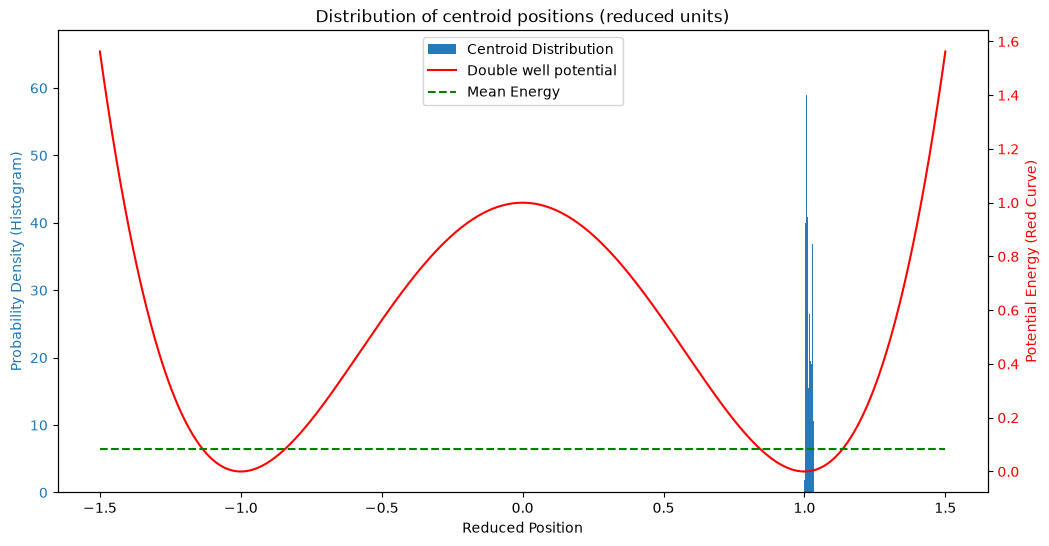

In [77]:
# Success rate calculation (should be between 40% and 50%, if not change dx)
success_rate = np.mean(success_list) * 100
print(f"Success rate: {success_rate:.2f}%")
P = params.P
a = params.a
V0 = params.V0
N = params.N

# Mean energy calculation
def mean_energy(M_conf):
    """
    Calculate the mean energy of the system for each configuration (<V> = 1/P * Sum(s=1 to P) V(x_s)).
    """
    return (1/P) *np.sum(V0 * ((M_conf / a)**2 - 1)**2, axis=1)

mean_energies = mean_energy(M_conf)
print(f"Mean energy: {np.mean(mean_energies) / const.e:.4e} eV")
print(f"Variance of energy: {np.var(mean_energies) / (const.e**2):.4e} eV^2")
mean_energy_prod = np.mean(mean_energies[int(np.ceil(N/2)):])  # Mean energy after equilibration (discard first half of the simulation)

# Centroid distribution calculation
def centroid_distribution(M_conf):
    """
    Calculate the centroid distribution of the system (x_c = 1/P * Sum(s=1 to P) x_s).
    """
    return (1/P) * np.sum(M_conf, axis=1)

centroid_positions = centroid_distribution(M_conf)
print(f"Mean centroid position: {np.mean(centroid_positions):.4e} m")
print(f"Mean controid position (reduced units): {np.mean(centroid_positions) / a:.4e} a")
print(f"Variance of centroid position: {np.var(centroid_positions):.4e} m^2")

# Plots
import matplotlib.pyplot as plt

## Plot energy evolution
plt.figure(figsize=(12, 6))
plt.plot(mean_energies / const.e)
plt.title('Potential energy of the particle evolution (eV)')

## Plot energy evolution with moving average
window_size = 1000
moving_avg = np.convolve(mean_energies / const.e, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
plt.plot(moving_avg)
plt.title(f'Potential energy of the particle evolution (eV) - Moving Average (window size = {window_size})')

## Plot centroid (reduced positions)
plt.figure(figsize=(12, 6))
plt.plot(centroid_positions/a)
plt.title('Centroid position evolution (reduced units)')

# Plot distribution of centroid positions (reduced position)
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.hist(centroid_positions / a, bins=50, density=True, alpha=0.97, color='tab:blue', label='Centroid Distribution')
ax1.set_xlabel('Reduced Position')
ax1.set_ylabel('Probability Density (Histogram)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
x = np.linspace(-1.5, 1.5, 1000)
y = (x**2 - 1)**2

ax2.plot(x, y, color='red', label='Double well potential')
ax2.plot(x, mean_energy_prod / V0 * np.ones_like(x), color='green', linestyle='--', label='Mean Energy')
ax2.set_ylabel('Potential Energy (Red Curve)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

plt.title('Distribution of centroid positions (reduced units)')
plt.show()




# Run simulation with P increasing

Success rate for P=1: 16.70%
Mean energy for P=1: 7.7264e-03 eV
Mean centroid position for P=1: -1.3281e-02 a
Success rate for P=2: 32.05%
Mean energy for P=2: 1.4975e-02 eV
Mean centroid position for P=2: -3.8798e-03 a
Success rate for P=5: 42.06%
Mean energy for P=5: 1.9323e-02 eV
Mean centroid position for P=5: -1.7524e-01 a
Success rate for P=10: 44.88%
Mean energy for P=10: 2.0199e-02 eV
Mean centroid position for P=10: 4.1964e-01 a
Success rate for P=20: 45.91%
Mean energy for P=20: 2.2507e-02 eV
Mean centroid position for P=20: 5.3654e-02 a
Success rate for P=35: 46.14%
Mean energy for P=35: 2.0159e-02 eV
Mean centroid position for P=35: 7.6136e-01 a
Success rate for P=50: 46.51%
Mean energy for P=50: 2.1795e-02 eV
Mean centroid position for P=50: 6.0890e-01 a
Success rate for P=75: 45.90%
Mean energy for P=75: 1.2277e-02 eV
Mean centroid position for P=75: 9.9078e-01 a
Success rate for P=100: 45.92%
Mean energy for P=100: 4.9981e-02 eV
Mean centroid position for P=100: 1.2928e+

Text(0, 0.5, 'Mean energy (eV)')

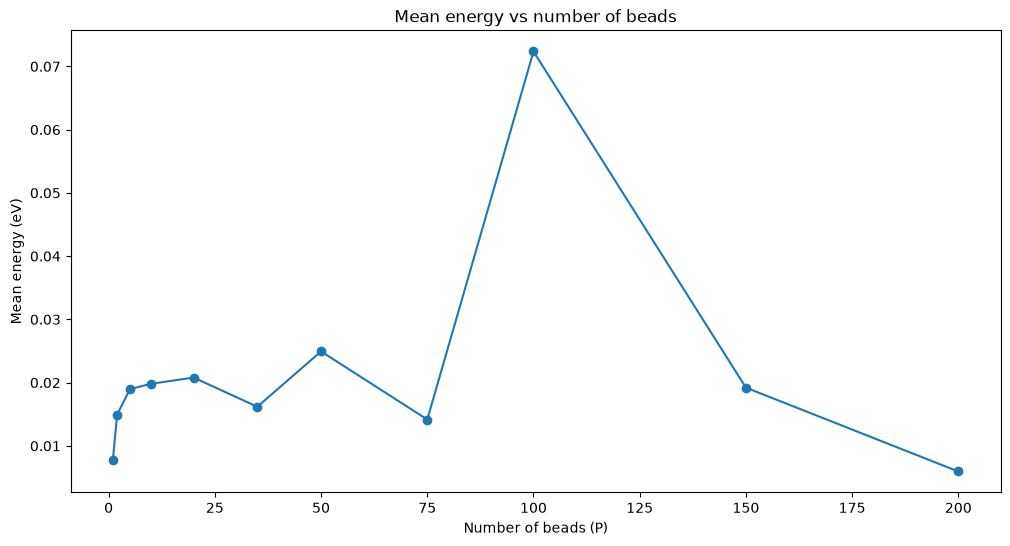

In [79]:
P_list = [1, 2, 5, 10, 20, 35, 50, 75, 100, 150, 200]
energy_list = []
for P in P_list:
    M_conf, success_list, params = run_simulation(100000, P)
    success_rate = np.mean(success_list) * 100
    print(f"Success rate for P={P}: {success_rate:.2f}%")
    print(f"Mean energy for P={P}: {np.mean(mean_energy(M_conf)) / const.e:.4e} eV")
    print(f"Mean centroid position for P={P}: {np.mean(centroid_distribution(M_conf)) / params.a:.4e} a")
    energy_list.append(np.mean(mean_energy(M_conf)[int(np.ceil(params.N/2)):]))  # Mean energy after equilibration (discard first half of the simulation)


# Plot mean energy vs number of beads
plt.figure(figsize=(12, 6))
plt.plot(P_list, np.array(energy_list) / const.e, marker='o')
plt.title('Mean energy vs number of beads')
plt.xlabel('Number of beads (P)')
plt.ylabel('Mean energy (eV)')